In [11]:
# ==========================================
# TA-03: DATA-DRIVEN MONTE CARLO SIMULATION
# Estimasi Risiko Keterlambatan Pengiriman
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Agar hasil simulasi dapat direproduksi
np.random.seed(42)

# Memuat dataset
df = pd.read_csv("../data/Food_Delivery_Times.csv")

# Menampilkan lima data pertama
print("Lima Data Pertama:")
display(df.head())

# Menampilkan informasi dataset
print("\nInformasi Dataset:")
df.info()

# Menampilkan ukuran dataset
print("\nJumlah baris dan kolom:", df.shape)

# Memeriksa nilai kosong
print("\nJumlah Nilai Kosong:")
print(df.isnull().sum())

# Memeriksa duplikasi
print("\nJumlah Baris Duplikat:", df.duplicated().sum())

# Statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

Lima Data Pertama:


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB

Jumlah baris dan kolom: (1000, 9)

Jumlah Nilai Kosong:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_T

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [12]:
# Membuat salinan dataset
data = df.copy()

# Menghapus baris yang tidak memiliki nilai durasi pengiriman
data = data.dropna(subset=["Delivery_Time_min"])

# Menghapus durasi yang tidak masuk akal
# Durasi pengiriman harus lebih besar dari nol
data = data[data["Delivery_Time_min"] > 0]

# Memeriksa kembali data
print("Jumlah data sebelum pembersihan:", len(df))
print("Jumlah data setelah pembersihan:", len(data))

print("\nNilai kosong pada variabel utama:")
print(data["Delivery_Time_min"].isnull().sum())

print("\nStatistik durasi pengiriman:")
display(data["Delivery_Time_min"].describe())

Jumlah data sebelum pembersihan: 1000
Jumlah data setelah pembersihan: 1000

Nilai kosong pada variabel utama:
0

Statistik durasi pengiriman:


count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64

In [13]:
# Mengambil variabel durasi pengiriman
delivery_time = data["Delivery_Time_min"]

# Menghitung parameter dari data
mu = delivery_time.mean()
sigma = delivery_time.std(ddof=1)

# Menentukan batas keterlambatan
threshold = 60

# Menghitung proporsi keterlambatan pada data
historical_late = (delivery_time > threshold).mean()

print("PARAMETER SIMULASI MONTE CARLO")
print("=" * 40)
print(f"Jumlah data       : {len(delivery_time)}")
print(f"Mean (mu)         : {mu:.3f} menit")
print(f"Standar deviasi   : {sigma:.3f} menit")
print(f"Batas keterlambatan: {threshold} menit")
print(f"Proporsi historis : {historical_late:.2%}")

PARAMETER SIMULASI MONTE CARLO
Jumlah data       : 1000
Mean (mu)         : 56.732 menit
Standar deviasi   : 22.071 menit
Batas keterlambatan: 60 menit
Proporsi historis : 41.50%


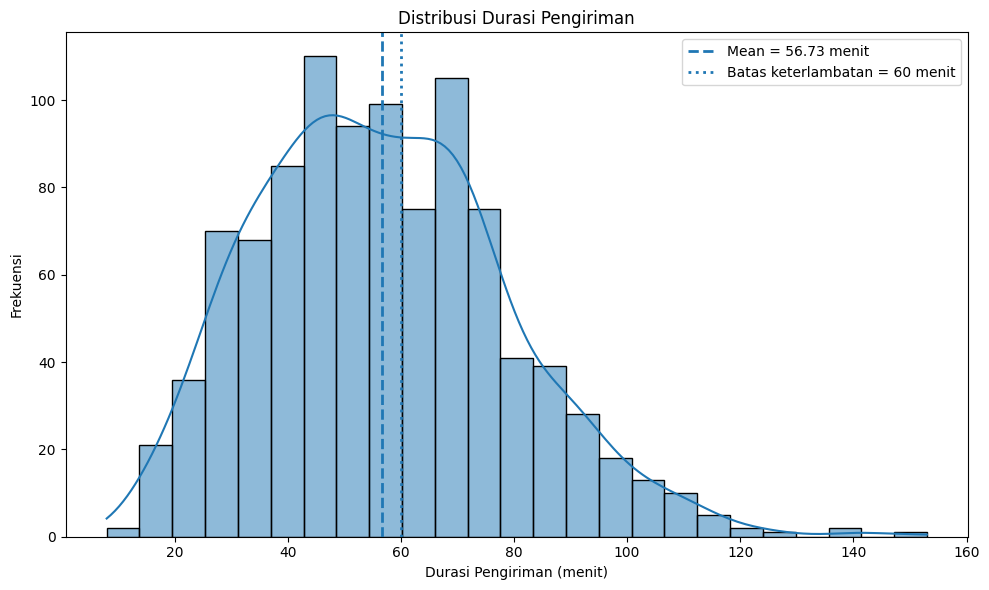

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    delivery_time,
    bins=25,
    kde=True
)

plt.axvline(
    mu,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mu:.2f} menit"
)

plt.axvline(
    threshold,
    linestyle=":",
    linewidth=2,
    label=f"Batas keterlambatan = {threshold} menit"
)

plt.title("Distribusi Durasi Pengiriman")
plt.xlabel("Durasi Pengiriman (menit)")
plt.ylabel("Frekuensi")

plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# SIMULASI MONTE CARLO
# Estimasi Risiko Keterlambatan Pengiriman
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Parameter simulasi
jumlah_simulasi = 10000
threshold = 60

# Mengambil data durasi pengiriman yang valid
delivery_time = data["Delivery_Time_min"].dropna()
delivery_time = delivery_time[delivery_time > 0].to_numpy()

# Menjalankan simulasi Monte Carlo empiris
np.random.seed(42)

hasil_simulasi = np.random.choice(
    delivery_time,
    size=jumlah_simulasi,
    replace=True
)

# Menghitung jumlah skenario terlambat
jumlah_terlambat = np.sum(hasil_simulasi > threshold)

# Menghitung probabilitas keterlambatan
probabilitas_terlambat = (
    jumlah_terlambat / jumlah_simulasi
) * 100

# Menghitung statistik hasil simulasi
rata_rata_simulasi = np.mean(hasil_simulasi)
std_simulasi = np.std(hasil_simulasi, ddof=1)
median_simulasi = np.median(hasil_simulasi)

print("HASIL SIMULASI MONTE CARLO")
print("=" * 45)
print(f"Jumlah simulasi          : {jumlah_simulasi:,}")
print(f"Rata-rata durasi         : {rata_rata_simulasi:.2f} menit")
print(f"Standar deviasi          : {std_simulasi:.2f} menit")
print(f"Median durasi            : {median_simulasi:.2f} menit")
print(f"Jumlah skenario terlambat: {jumlah_terlambat:,}")
print(f"Probabilitas terlambat   : {probabilitas_terlambat:.2f}%")

HASIL SIMULASI MONTE CARLO
Jumlah simulasi          : 10,000
Rata-rata durasi         : 56.64 menit
Standar deviasi          : 22.14 menit
Median durasi            : 55.00 menit
Jumlah skenario terlambat: 4,104
Probabilitas terlambat   : 41.04%


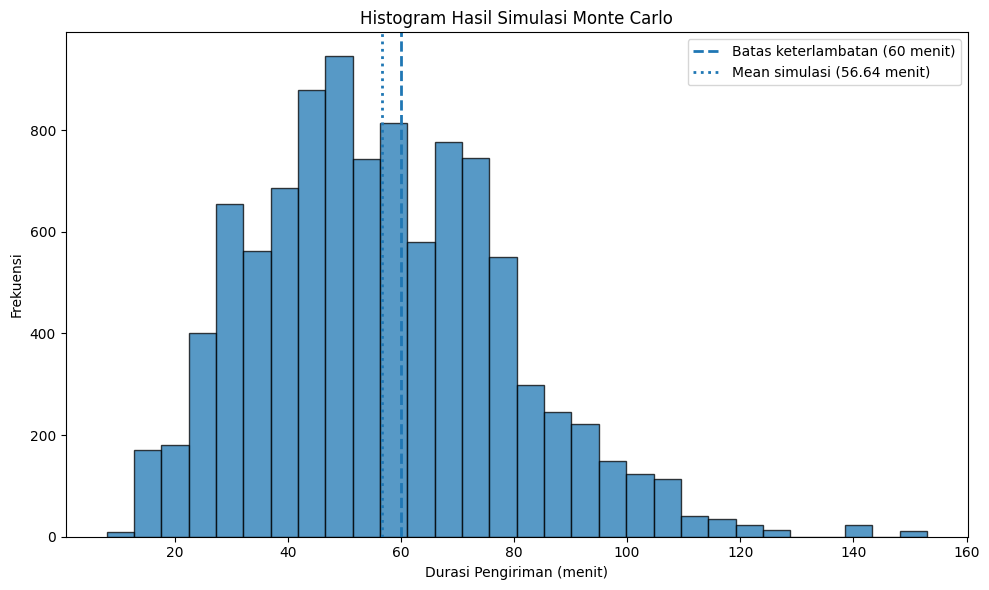

In [16]:
# ==========================================
# VISUALISASI HASIL SIMULASI
# ==========================================

plt.figure(figsize=(10, 6))

plt.hist(
    hasil_simulasi,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Batas keterlambatan ({threshold} menit)"
)

plt.axvline(
    rata_rata_simulasi,
    linestyle=":",
    linewidth=2,
    label=f"Mean simulasi ({rata_rata_simulasi:.2f} menit)"
)

plt.title("Histogram Hasil Simulasi Monte Carlo")
plt.xlabel("Durasi Pengiriman (menit)")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()

PERBANDINGAN PROBABILITAS KETERLAMBATAN
Probabilitas data asli : 41.50%
Probabilitas simulasi  : 41.04%
Selisih                : 0.46 poin persentase


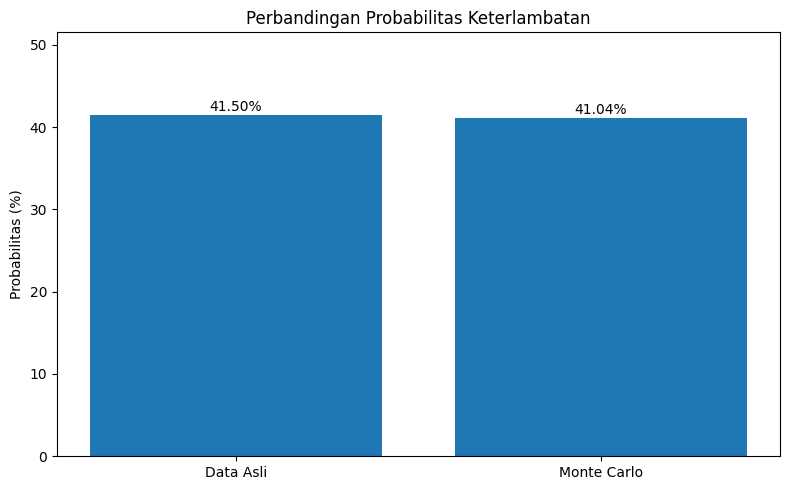

In [17]:
# ==========================================
# PERBANDINGAN DATA ASLI DAN HASIL SIMULASI
# ==========================================

# Proporsi keterlambatan pada data asli
prob_historis = np.mean(delivery_time > threshold) * 100

# Proporsi keterlambatan pada hasil simulasi
prob_simulasi = np.mean(hasil_simulasi > threshold) * 100

# Menghitung selisih absolut
selisih = abs(prob_historis - prob_simulasi)

print("PERBANDINGAN PROBABILITAS KETERLAMBATAN")
print("=" * 50)
print(f"Probabilitas data asli : {prob_historis:.2f}%")
print(f"Probabilitas simulasi  : {prob_simulasi:.2f}%")
print(f"Selisih                : {selisih:.2f} poin persentase")

# Membuat grafik perbandingan
labels = ["Data Asli", "Monte Carlo"]
values = [prob_historis, prob_simulasi]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.title("Perbandingan Probabilitas Keterlambatan")
plt.ylabel("Probabilitas (%)")
plt.ylim(0, max(values) + 10)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()